## Завдання 1. Decision Tree Regressor

**Побудуйте дерево рішень і перевірте, наскільки добре воно передбачає ціни на житло.**

### Умова:

1. Завантажте датасет `California Housing`.
2. Використовуйте ознаки:

   * `MedInc`
   * `HouseAge`
   * `AveRooms`
   * `AveBedrms`
3. Розділіть дані на train/test (80/20, `random_state=42`).
4. Навчіть модель:

   * `DecisionTreeRegressor(max_depth=4, random_state=42)`
5. Обчисліть R² на тестовій вибірці.


In [34]:

import numpy as np
from sklearn.metrics import accuracy_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeRegressor
import pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
from xgboost import XGBRegressor

# Завантаження датасету
housing = fetch_california_housing()
X = housing.data
y = housing.target
feature_names = housing.feature_names

# Створення DataFrame для зручності
df = pd.DataFrame(X, columns=feature_names)
df['target'] = y

print("Розмір датасету:", df.shape)
df.head()

Розмір датасету: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,target
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [35]:

# Вибір ознак
features = ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms']
X_selected = df[features].values
y = df['target'].values

# Розділення
X_train, X_test, y_train, y_test = train_test_split(
    X_selected, y, test_size=0.2, random_state=42)

model = DecisionTreeRegressor(max_depth=4, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
r2 = r2_score(y_test, y_pred)
print(f"Decision Tree R²: {r2:.4f}")

Decision Tree R²: 0.5075


## Завдання 3. XGBoost vs Random Forest

**Побудуйте модель градієнтного бустингу і порівняйте її з результатами випадкового лісу.**

### Умова:

1. Використовуйте ті самі дані (California Housing).
2. Навчіть модель:

   * `XGBRegressor(n_estimators=200, learning_rate=0.1, max_depth=5, random_state=42)`
3. Обчисліть R² на тестовій вибірці.
4. Порівняйте результат із Random Forest із Завдання 2.

| Model         | R² Test |
| ------------- | ------- |
| Random Forest | ...     |
| XGBoost       | ...     |


In [36]:

# Вибір ознак
features = ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms']
X_selected = df[features].values
y = df['target'].values

# Розділення
X_train, X_test, y_train, y_test = train_test_split(
    X_selected, y, test_size=0.2, random_state=42)

model = DecisionTreeRegressor(max_depth=4, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
r2 = r2_score(y_test, y_pred)

model_r = RandomForestRegressor(n_estimators=100, random_state=42)
model_r.fit(X_train, y_train)
y_pred = model_r.predict(X_test)
r2_r = r2_score(y_test, y_pred)

results = pd.DataFrame({
    "Model": ["Dec Tree", "Rand Forrest"],
    "R^2": [r2, r2_r],
})
display(results)

,Model,R^2
0,Dec Tree,0.507482
1,Rand Forrest,0.587887


## Завдання 3. Градієнтний бустинг (XGBoost)

Побудуйте модель градієнтного бустингу і порівняйте її з результатами випадкового лісу.

### Умова:

1. Використовуйте ті самі дані (California Housing).
2. Навчіть модель `XGBRegressor(n_estimators=200, learning_rate=0.1, max_depth=5, random_state=42)`.
3. Обчисліть R² на тестовій вибірці.
4. Порівняйте результат із Random Forest із Завдання 2.

In [37]:


model_x = XGBRegressor(n_estimators=200, learning_rate=0.1, max_depth=5, random_state=42)
model_x.fit(X_train, y_train)
y_pred = model_x.predict(X_test)
r2_x = r2_score(y_test, y_pred)

results = pd.DataFrame({
    "Model": ["Dec Tree", "Rand Forrest", "XGB"],
    "R^2": [r2, r2_r, r2_x],
})
display(results)

,Model,R^2
0,Dec Tree,0.507482
1,Rand Forrest,0.587887
2,XGB,0.599275


## Завдання 4. Logistic Regression — Classification

**Спробуйте розв'язати задачу класифікації на основі цін на житло.**

### Умова:

1. Використовуйте датасет `California Housing`.
2. Перетворіть цільову змінну на бінарну:

   * **Клас 1** — якщо ціна вища за медіану.
   * **Клас 0** — якщо ціна нижча або дорівнює медіані.
3. Для цього обчисліть медіану та створіть нову цільову змінну:

   * `median_price = np.median(y)`
   * `y_class = (y > median_price).astype(int)`
4. Розділіть дані на train/test (80/20, `random_state=42`).
5. Навчіть модель:

   * `LogisticRegression(max_iter=1000)`
6. Побудуйте `Confusion Matrix`.
7. Обчисліть метрики класифікації:

   * **Accuracy**
   * **Precision**
   * **Recall**
   * **F1-score**


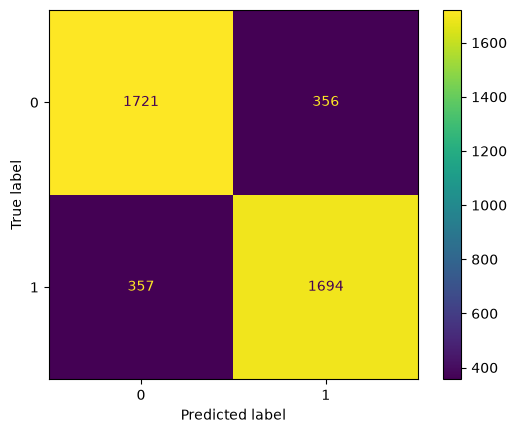

Metric,Result
Accuracy Score,0.827277
Precision Score,0.827271
Recall Score,0.827269
F1 Score,0.827270


In [42]:
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split

median_price = np.median(y)
y_class = (y > median_price).astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y_class, test_size=0.2, random_state=42)

model = LogisticRegression(max_iter=10000, random_state=42) # With max_iter=1000 i got warning so after increasing it all good
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

cm = confusion_matrix(y_test, y_pred, labels=model.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)
disp.plot()
plt.show()

accuracy_score1 = accuracy_score(y_test, y_pred, normalize=True)

precision_score1 = precision_score(y_test, y_pred, average='macro', zero_division=np.nan)

recall_score1 = recall_score(y_test, y_pred, average='macro', zero_division=np.nan)

f1_score1 = f1_score(y_test, y_pred, average='macro')

results = pd.DataFrame({
    "Metric": ["Accuracy Score", "Precision Score", "Recall Score", "F1 Score"],
    "Result": [accuracy_score1, precision_score1, recall_score1, f1_score1],
})
display(results.style.hide(axis="index"))